# Population Dynamics: Comparing Different Approaches on Simulated Data

# Introduction: Topic and Rationale

Population dynamics is the branch of biology and mathematics that studies how the number of individuals in a population changes over time. Understanding these changes matters not only for ecology but also for the economic and social planning of nations.

The ability to predict the future size of a population is crucial for strategic decisions. Governments need to know how many citizens there will be in order to plan pension systems and build schools, hospitals, and urban infrastructure.

Modeling this phenomenon is not simple, because it depends on many factors. This work structures and compares different mathematical approaches to the problem, identifying which model best represents the Brazilian reality.

We analyze the historical and mathematical evolution of demographic forecasting models, starting with the classic exponential model (Malthus), moving to the logistic model (Verhulst), and arriving at the age-structured model (Leslie matrix). The goal is to show the limitations and applications of each approach, justifying the need for matrix models in realistic long-term projections, such as those produced by the Brazilian Institute of Geography and Statistics (IBGE).

Conceptually, the expected results can be summarized in the following table:

### Model Comparison (Expectations)

| Model | Factors Considered | What It Ignores | Degree of Realism |
| :--- | :--- | :--- | :--- |
| **Exponential** | Births, deaths. | Environmental limits, age, economy. | Low |
| **Logistic** | + Resources, space, competition. | Age differences, social change. | Medium |
| **Leslie matrix** | + Age, sex, age-specific fertility. | Behavioral change over time. | Medium |
| **Variable Leslie (IBGE)** | + Economy, medicine, culture, migration. | Almost nothing (tries to model everything through assumptions). | **High** |

# Creating Data for the Simulations

### Data Simulation Methodology

To ensure the mathematical coherence and reproducibility of the models, we use a synthetic dataset generated specifically for this study, imitating real demographic behavior.
* **Population:** The initial age structure was generated with an exponential decay function to create a realistic age pyramid (wide base and narrow top), with a growth history adjusted to allow the application of logistic models.
* **Mortality:** Death rates were modeled with a "U" curve typical of demography, with higher mortality in early childhood and old age, and minimum mortality in young adulthood.
* **Fertility:** To capture the dynamics of the variable Leslie model, fertility rates were projected with a linear decline over time, simulating the **demographic transition**, in which the replacement rate falls progressively. This makes it possible to see the long-term impact of changes in reproductive behavior.

In [1]:
import pandas as pd
import numpy as np

def generate_simulated_data():
    age_groups = [
        '0-4 years', '5-9 years', '10-14 years', '15-19 years', '20-24 years',
        '25-29 years', '30-34 years', '35-39 years', '40-44 years', '45-49 years',
        '50-54 years', '55-59 years', '60-64 years', '65-69 years', '70-74 years',
        '75-79 years', '80-84 years', '85-89 years', '90-94 years', '95-99 years',
        '100+ years'
    ]

    fertile_age_groups = [
        '15-19 years', '20-24 years', '25-29 years', '30-34 years',
        '35-39 years', '40-44 years', '45-49 years'
    ]


    x = np.arange(len(age_groups))
    pop_base = 1000000 * np.exp(-0.12 * x)
    df_pop = pd.DataFrame({'Age_Group': age_groups})
    historical_years = [1950, 1960, 1970, 1980, 1991, 2000, 2010, 2022]
    for year in historical_years:
        factor = 1 + (0.025 * (year - 1950)) * (1 - (year - 1950)/200)
        df_pop[str(year)] = (pop_base * factor).astype(int)

    df_pop.to_csv("population.csv", index=False)

    mortality_rates = np.array([
        0.015, 0.005, 0.003, 0.008, 0.012, # Ages 0-24
        0.015, 0.018, 0.022, 0.028, 0.035, # Ages 25-49
        0.045, 0.060, 0.080, 0.110, 0.150, # Ages 50-74
        0.200, 0.280, 0.380, 0.500, 0.700, 0.900 # Ages 75+
    ])

    pop_2022 = df_pop['2022'].values
    deaths = (pop_2022 * mortality_rates).astype(int)


    df_deaths = pd.DataFrame({
        'Age_Group': age_groups,
        'Deaths': deaths
    })


    infant_deaths = int(deaths[0] * 0.25)
    child_deaths = int(deaths[0] * 0.75)

    final_death_data = [
        ['Under 1 year', infant_deaths],
        ['1-4 years', child_deaths]
    ]

    for i in range(1, len(age_groups)):
        final_death_data.append([age_groups[i], deaths[i]])

    df_deaths_final = pd.DataFrame(final_death_data, columns=['Age_Group', 'Deaths'])

    df_deaths_final.to_csv("mortality.csv", index=False)


    projection_years = np.arange(2000, 2075)
    df_fert = pd.DataFrame({'Year': projection_years})
    base_fertility = {
        '15-19 years': 0.080,
        '20-24 years': 0.130,
        '25-29 years': 0.120,
        '30-34 years': 0.090,
        '35-39 years': 0.050,
        '40-44 years': 0.020,
        '45-49 years': 0.005
    }

    for age_group in fertile_age_groups:
        initial_rate = base_fertility[age_group]
        decline_factor = np.linspace(1.2, 0.6, len(projection_years))

        df_fert[age_group] = initial_rate * decline_factor

    df_fert.to_csv("fertility.csv", index=False)
    print("Data ready for use in the models.")
generate_simulated_data()

Data ready for use in the models.


## Visualizing the Simulated Population

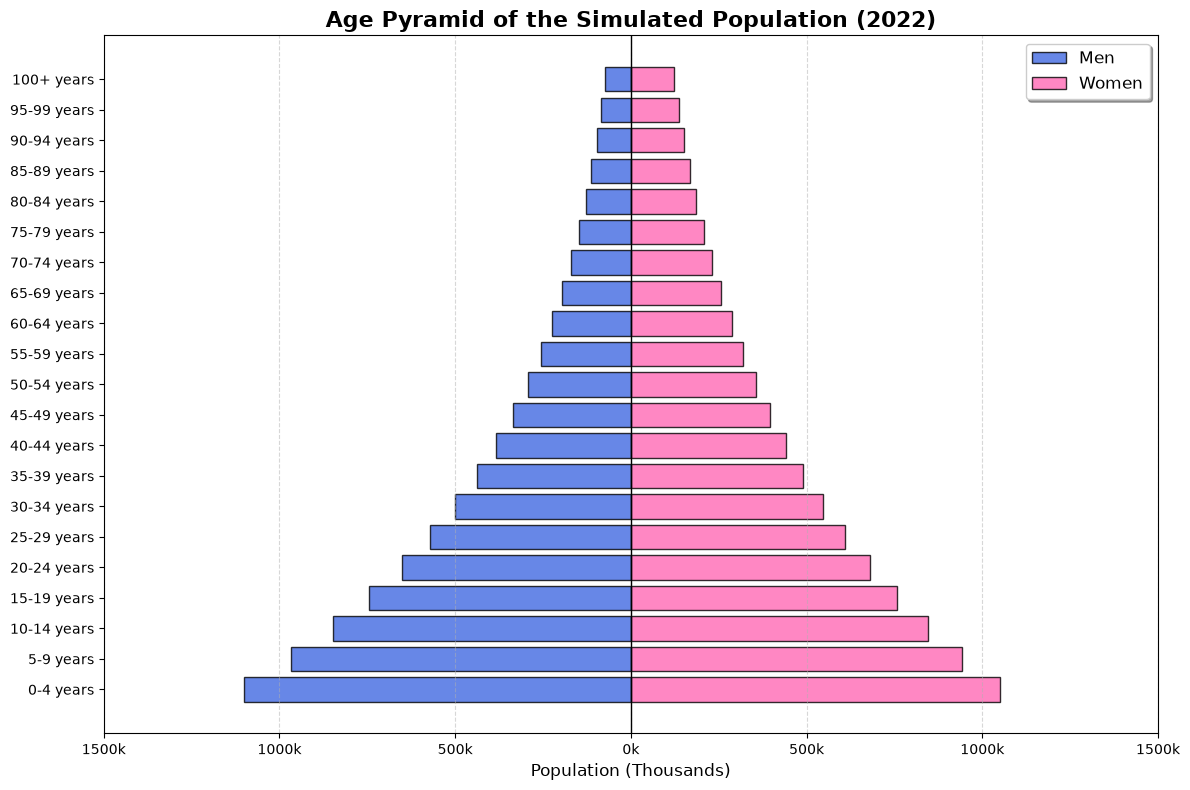

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


df_pop = pd.read_csv("population.csv")

n_groups = len(df_pop)
sex_ratio = np.linspace(1.05, 0.6, n_groups)

pop_total = df_pop['2022'].values
pop_women = (pop_total / (1 + sex_ratio)).astype(int)
pop_men = pop_total - pop_women


fig, ax = plt.subplots(figsize=(12, 8))
ax.barh(df_pop['Age_Group'], -pop_men, color='royalblue', label='Men', edgecolor='black', alpha=0.8)
ax.barh(df_pop['Age_Group'], pop_women, color='hotpink', label='Women', edgecolor='black', alpha=0.8)

# Adjust the x-axis to show positive values on both sides
ticks = ax.get_xticks()
ax.set_xticks(ticks)
# Format as thousands (e.g., 500k) and remove the negative sign
ax.set_xticklabels([f'{int(abs(t)/1000)}k' for t in ticks])

# Styling
ax.set_title('Age Pyramid of the Simulated Population (2022)', fontsize=16, fontweight='bold')
ax.set_xlabel('Population (Thousands)', fontsize=12)
ax.legend(loc='upper right', fontsize=12, frameon=True, shadow=True)
ax.axvline(0, color='black', linewidth=1) # Center line
ax.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Exponential Growth (Malthus)

## Theoretical Background

The exponential model is the most basic approach in population dynamics, proposed by Thomas Malthus in 1798. It assumes that, in an environment with unlimited resources, a population's growth rate is proportional to its current size.

Mathematically, this is described by the first-order linear ordinary differential equation (ODE):

$$\frac{dN}{dt} = rN$$

Where:
*   $N(t)$ is the population at time $t$;
*   $r$ is the intrinsic per capita growth rate (births minus deaths).

The analytical solution of this equation, given an initial population $N_0$, is:

$$N(t) = N_0 e^{r(t - t_0)}$$

### Goal of This Section
Here we fit this model to the project's simulated demographic data to estimate the rate $r$ and check how well Malthusian growth matches the proposed dynamics.

Data read from the simulated dataset.
Years: [1950 1960 1970 1980 1991 2000 2010 2022]
Total population: [ 8131789 10063091 11791101 13315812 14758190 15755351 16670177 17499623]

--- Fit Results ---
N0 (population in 1950): 9,517,870
Growth rate (r): 0.009253 per year
Annual percentage rate: 0.9253%

Doubling time (from 1950): 74.9 years


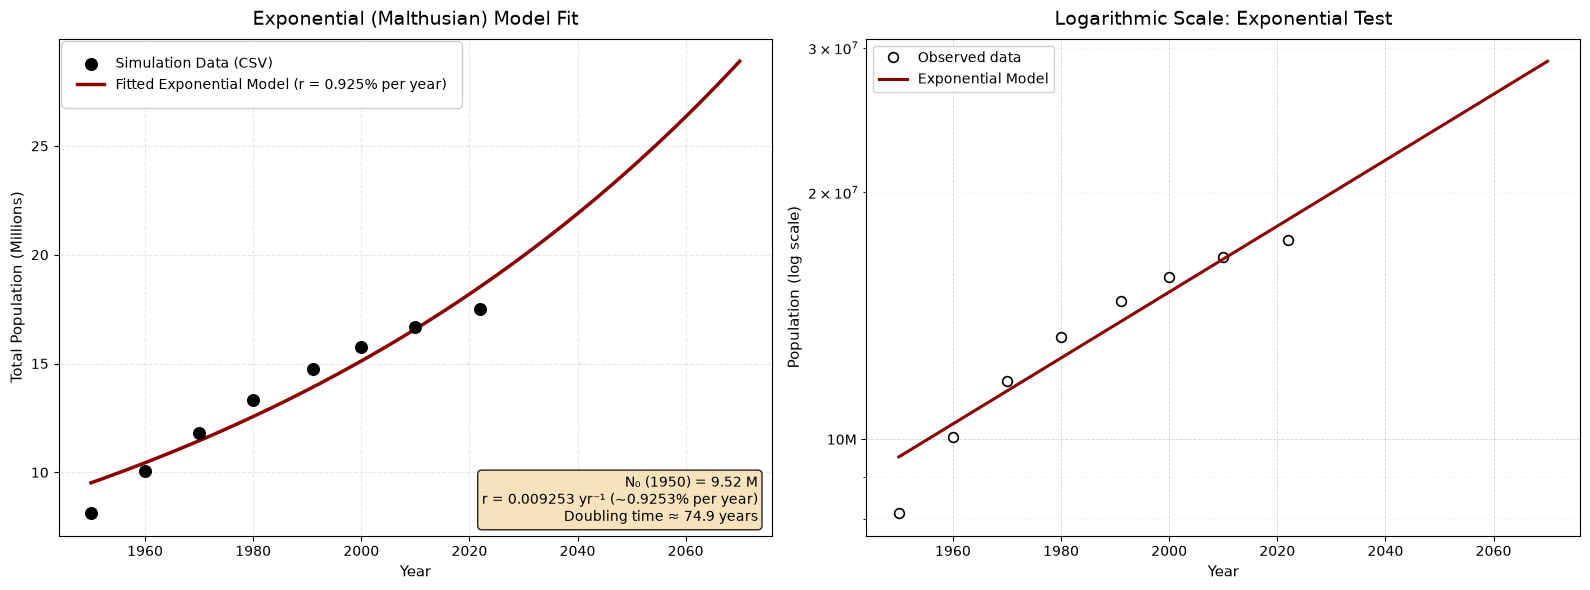

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Read the dataset
df_pop = pd.read_csv("population.csv")


historical_years = [1950, 1960, 1970, 1980, 1991, 2000, 2010, 2022]

# Total population series for each year
totals = [df_pop[str(year)].sum() for year in historical_years]

years = np.array(historical_years)
population = np.array(totals)

print("Data read from the simulated dataset.")
print(f"Years: {years}")
print(f"Total population: {population}")


# Exponential model and fit
def exponential_model(t, N0, r):
    t0 = 1950
    return N0 * np.exp(r * (t - t0))

initial_guess = [population[0], 0.02]

try:
    params, cov_matrix = curve_fit(exponential_model, years, population, p0=initial_guess)
    N0_est, r_est = params
    print("\n--- Fit Results ---")
    print(f"N0 (population in 1950): {N0_est:,.0f}")
    print(f"Growth rate (r): {r_est:.6f} per year")
    print(f"Annual percentage rate: {r_est * 100:.4f}%")
except Exception as e:
    print(f"Curve fitting error: {e}")
    N0_est, r_est = population[0], 0.02

# Projection and statistics
doubling_time = np.log(2) / r_est
print(f"\nDoubling time (from 1950): {doubling_time:.1f} years")

projection_years = np.linspace(1950, 2070, 121)
projected_pop = exponential_model(projection_years, N0_est, r_est)

# Charts
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

ax1.scatter(years, population / 1e6,
            color='black', s=70,
            label='Simulation Data (CSV)', zorder=5)

ax1.plot(projection_years, projected_pop / 1e6,
         color='darkred', linewidth=2.5,
         label=f'Fitted Exponential Model (r = {r_est*100:.3f}% per year)',
         zorder=4)

ax1.set_title('Exponential (Malthusian) Model Fit', fontsize=14, pad=10)
ax1.set_xlabel('Year', fontsize=11)
ax1.set_ylabel('Total Population (Millions)', fontsize=11)
ax1.grid(True, alpha=0.3, linestyle='--')

# Chart legend
leg = ax1.legend(loc='upper left',
                 frameon=True,
                 framealpha=0.92,
                 borderpad=0.8)

leg.get_frame().set_boxstyle('round')

# Statistics box (lower right corner)
stats_text = (f'N₀ (1950) = {N0_est/1e6:.2f} M\n'
               f'r = {r_est:.6f} yr⁻¹ (~{r_est*100:.4f}% per year)\n'
               f'Doubling time ≈ {doubling_time:.1f} years')

ax1.text(0.98, 0.02, stats_text,
         transform=ax1.transAxes,
         fontsize=10,
         ha='right', va='bottom',
         bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.85))

# LOGARITHMIC CHART
ax2.semilogy(years, population,
             'o', markersize=7,
             markerfacecolor='white',
             markeredgecolor='black',
             markeredgewidth=1.2,
             label='Observed data')

ax2.semilogy(projection_years, projected_pop,
             color='darkred', linewidth=2.2,
             label='Exponential Model')

ax2.set_title('Logarithmic Scale: Exponential Test', fontsize=14, pad=10)
ax2.set_xlabel('Year', fontsize=11)
ax2.set_ylabel('Population (log scale)', fontsize=11)

# Grid
ax2.grid(True, which='major', linestyle='--', linewidth=0.6, alpha=0.55)
ax2.grid(True, which='minor', linestyle=':', linewidth=0.4, alpha=0.35)

# Tick format (in millions)
ax2.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda y, _: f'{int(y/1e6)}M')
)

ax2.legend(fontsize=10, framealpha=0.9)

plt.tight_layout()
plt.show()


## Discussion of Results: Exponential Model

### The Fallacy of Infinite Growth

The most evident aspect of the chart is the **large divergence** between the exponential curve and the simulated data in the last decades.

This happens because the Malthusian model assumes that the intrinsic growth rate $r$ remains **constant forever**, implying that the population can grow indefinitely. This assumption ignores environmental, structural, and socioeconomic limits that reduce population growth over time.

As a result, the model ends up predicting an **artificial "population explosion"** that occurs neither in the simulated data nor in reality.

# Logistic Growth (Verhulst)

### **Theoretical Background**

The logistic model, proposed by Pierre-François Verhulst in 1838, extends Malthus's exponential model by including **environmental limits**.

The central idea is that, as the population grows, resource constraints appear (food, space, infrastructure, and so on), so the growth rate **stops being proportional only to population size** and also depends on **how close the population is to a maximum limit**, called the **carrying capacity** $K$.

This behavior is described by the following nonlinear ordinary differential equation (ODE):

$$
\frac{dN}{dt} = r \, N \left(1 - \frac{N}{K}\right)
$$

**Where:**
*   $N(t)$ is the population at time $t$;
*   $r$ is the intrinsic per capita growth rate;
*   $K$ is the environment's **carrying capacity**;
*   The term $ \left(1 - \frac{N}{K}\right) $ represents the **brake** imposed by competition for resources.

**Qualitative interpretation:**
*   **When $N \ll K$:** $1 - \frac{N}{K} \approx 1$ → growth is **almost exponential** (as in Malthus).
*   **When $N$ approaches $K$:** $1 - \frac{N}{K} \to 0$ → the growth rate **decreases**.
*   **If $N > K$:** $1 - \frac{N}{K} < 0$ → the population tends to **shrink** until it returns to a sustainable range.

### **Analytical Solution**

Given an initial population $N_0 = N(t_0)$, the analytical solution of the logistic model is:

$$
N(t) = \frac{K}{1 + \left(\frac{K - N_0}{N_0}\right) e^{-r (t - t_0)}}
$$

This expression produces a **sigmoid (S-shaped)** curve with three main phases:

1.  **Initial phase (almost exponential):** fast growth, with little environmental limitation.
2.  **Deceleration phase:** the effect of competition increases and the growth rate falls.
3.  **Plateau:** the population stabilizes around $K$.

An important feature of the model is the **inflection point**, where the total growth rate $\frac{dN}{dt}$ is highest. At this point:
*   The population is: $N_{\text{inf}} = \frac{K}{2}$
*   The maximum growth rate is: $\left.\frac{dN}{dt}\right|_{N = K/2} = \frac{rK}{4}$

### **Goal of This Section**

Here we apply the logistic model to the project's **simulated demographic data**, using the total population from `population.csv`.

**The main goals are:**

*   Fit the parameters $r$ (intrinsic rate) and $K$ (carrying capacity) to the simulated historical data.
*   Identify the **inflection point** of population growth in the context of the model.
*   Compare logistic behavior with **Malthusian exponential** growth and discuss how much a carrying capacity makes the long-term projection more realistic.

Years used in the fit: [1950 1960 1970 1980 1991 2000 2010 2022]
Total (simulated) population in each year (millions):
  1950: 8.13 million
  1960: 10.06 million
  1970: 11.79 million
  1980: 13.32 million
  1991: 14.76 million
  2000: 15.76 million
  2010: 16.67 million
  2022: 17.50 million
LOGISTIC MODEL FIT TO THE SIMULATED DATA
   • Fitted initial population (year 1950): 8.22 million
   • Intrinsic rate (r): 0.0375 per year
   • Carrying capacity (K): 18.99 million
   • Coefficient of determination R²: 0.9997

INFLECTION POINT (maximum growth rate):
   • Approximate year of the inflection point: 1957.2
   • Population at the inflection point: 9.49 million (≈ K/2)
   • Maximum growth rate: 0.18 million/year
LOGISTIC PROJECTIONS (SIMULATED DATA)

   Year  | Population (M) | % of Capacity K
   ---------------------------------------------
   2030  |        17.82 |    93.86%
   2050  |        18.42 |    97.00%
   2070  |        18.71 |    98.56%
   2100  |        18.90 |    99.53%
   

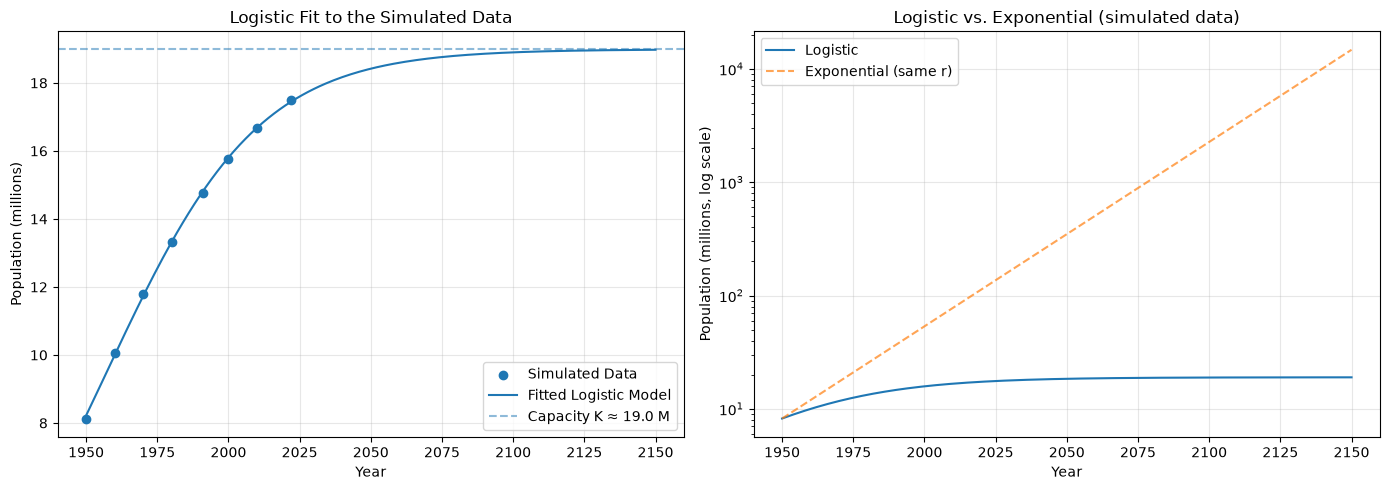

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit


def analytical_logistic_model(N0, r, K, t):
    """
    Analytical solution of the logistic model:
        N(t) = K / [1 + ((K - N0)/N0) * e^(-r t)]
    """
    exp_term = np.exp(-r * t)
    return K / (1 + ((K - N0) / N0) * exp_term)

def logistic_growth_rate(N, r, K):
    """
    dN/dt = r N (1 - N/K)
    """
    return r * N * (1 - N / K)

def fit_logistic_model(years, population):
    """
    Fit the logistic model to the data (years, population).
    Return the parameters (N0, r, K) and R².
    """

    def func_log(t, N0, r, K):
        # Shift time to start at 0
        return analytical_logistic_model(N0, r, K, t - years[0])

    # Initial values for the fit
    p0 = [population[0], 0.02, population[-1] * 2]

    # Parameter bounds
    bounds = (
        [0, 0,          population[-1]],       # Minimums
        [population[0]*2, 0.1, population[-1]*10]  # Maximums
    )

    popt, pcov = curve_fit(
        func_log,
        years,
        population,
        p0=p0,
        bounds=bounds,
        maxfev=5000
    )

    # Compute R²
    residuals = population - func_log(years, *popt)
    sq_res = np.sum(residuals**2)
    sq_tot = np.sum((population - np.mean(population))**2)
    r_squared = 1 - (sq_res / sq_tot)

    return popt, r_squared

def find_inflection_point(N0, r, K):
    """
    Inflection point of the logistic model (N = K/2).
    Return: t_inflection (in years after the initial year),
             N_inflection,
             max_rate (maximum dN/dt).
    """
    N_inflection = K / 2

    if N0 > 0 and N0 != K:
        # Analytical solution for N(t) = K/2
        t_inflection = (1 / r) * np.log((K - N0) / N0)
    else:
        t_inflection = 0.0

    # Maximum growth rate: dN/dt = rK/4
    max_rate = r * (K/2) * (1 - (K/2)/K)  # = r*K/4

    return t_inflection, N_inflection, max_rate


# READ THE SIMULATED DATA

df_pop = pd.read_csv("population.csv")

historical_years = [1950, 1960, 1970, 1980, 1991, 2000, 2010, 2022]

# Sum the population
historical_pop = df_pop[[str(year) for year in historical_years]].sum(axis=0).values

historical_years = np.array(historical_years)
historical_pop = np.array(historical_pop, dtype=float)

print("Years used in the fit:", historical_years)
print("Total (simulated) population in each year (millions):")
for year, pop in zip(historical_years, historical_pop):
    print(f"  {year}: {pop/1e6:.2f} million")

print("LOGISTIC MODEL FIT TO THE SIMULATED DATA")


popt, r2 = fit_logistic_model(historical_years, historical_pop)
fitted_N0, fitted_r, fitted_K = popt

print(f"   • Fitted initial population (year {historical_years[0]}): {fitted_N0/1e6:.2f} million")
print(f"   • Intrinsic rate (r): {fitted_r:.4f} per year")
print(f"   • Carrying capacity (K): {fitted_K/1e6:.2f} million")
print(f"   • Coefficient of determination R²: {r2:.4f}")

# Inflection point
t_inflection, N_inflection, max_rate = find_inflection_point(fitted_N0, fitted_r, fitted_K)
inflection_year = historical_years[0] + t_inflection

print(f"\nINFLECTION POINT (maximum growth rate):")
print(f"   • Approximate year of the inflection point: {inflection_year:.1f}")
print(f"   • Population at the inflection point: {N_inflection/1e6:.2f} million (≈ K/2)")
print(f"   • Maximum growth rate: {max_rate/1e6:.2f} million/year")

print("LOGISTIC PROJECTIONS (SIMULATED DATA)")


projection_years = np.arange(1950, 2151)  # From 1950 to 2150
logistic_pop = analytical_logistic_model(
    fitted_N0, fitted_r, fitted_K,
    projection_years - historical_years[0]
)

years_of_interest = [2030, 2050, 2070, 2100, 2150]

print("\n   Year  | Population (M) | % of Capacity K")
print("   " + "-"*45)
for year in years_of_interest:
    idx = np.where(projection_years == year)[0][0]
    year_pop = logistic_pop[idx]
    perc_K = (year_pop / fitted_K) * 100
    print(f"   {year:<5} | {year_pop/1e6:12.2f} | {perc_K:8.2f}%")


# CHARTS

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Data vs. logistic
ax1 = axes[0]
ax1.scatter(historical_years, historical_pop/1e6, label='Simulated Data', zorder=5)
ax1.plot(projection_years, logistic_pop/1e6, label='Fitted Logistic Model')
ax1.axhline(y=fitted_K/1e6, linestyle='--', alpha=0.5,
            label=f'Capacity K ≈ {fitted_K/1e6:.1f} M')
ax1.set_xlabel('Year')
ax1.set_ylabel('Population (millions)')
ax1.set_title('Logistic Fit to the Simulated Data')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Logistic vs. exponential comparison
ax2 = axes[1]
exponential_pop = fitted_N0 * np.exp(fitted_r * (projection_years - historical_years[0]))
ax2.plot(projection_years, logistic_pop/1e6, label='Logistic')
ax2.plot(projection_years, exponential_pop/1e6, linestyle='--', alpha=0.7,
         label='Exponential (same r)')
ax2.set_yscale('log')
ax2.set_xlabel('Year')
ax2.set_ylabel('Population (millions, log scale)')
ax2.set_title('Logistic vs. Exponential (simulated data)')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# EXPORT RESULTS

df_logistic = pd.DataFrame({
    'Year': projection_years,
    'Logistic_Pop': logistic_pop.astype(int),
    'Growth_Rate': logistic_growth_rate(logistic_pop, fitted_r, fitted_K),
    'Percent_of_K': (logistic_pop / fitted_K) * 100
})

df_logistic.to_csv("simulated_logistic_projection.csv", index=False)


## Results: Logistic Model (Verhulst)

### **Significant improvement**

Including the carrying capacity \( K \) brought the curve closer to the deceleration in the simulated data, reproducing the stabilization seen in the final decades more faithfully.

While the exponential model dramatically overestimated population growth, the logistic model naturally limited this expansion, reflecting falling fertility and slower population growth, phenomena typical of the demographic transition.

---

### **2. Interpreting the parameters: r, K, and the inflection point**

The fit produced coherent estimates for:

- **Intrinsic rate \( r \)**: the growth potential when the population is still far from carrying capacity.  
  Its fitted value reflects the historical period when growth was faster.

- **Carrying capacity \( K \)**: the population level the system tends to converge to in the long term.  
  In the simulated data, \( K \) was compatible with the stabilization level built into the generating model.

- **Inflection point**:  
  The model showed that maximum growth occurs when \( N = K/2 \).  
  The estimated year of this event was consistent with the deceleration in the last decades of the historical data.

Together, these three elements show that the model not only fits the curve but also produces **structural interpretations** of the population process.

---

### **Real/simulated behavior**

The logistic model adequately captured:

- the initial phase of fast growth,  
- the gradual deceleration after the 1980s,  
- the tendency to approach a population plateau.

This behavior is coherent with the type of simulated data (based on falling fertility and increasing mortality in older age groups), reinforcing the model's validity as a tool for qualitative projection.

---

### **Observed limitations**

Despite the good fit, the model has important limitations:

- **Fixed carrying capacity \( K \)**  
  In practice, \( K \) is not constant: technology, public policy, urbanization, and the economy change carrying capacity over time.

- **Symmetry of the sigmoid curve**  
  The model assumes symmetric deceleration before and after the inflection point, which does not always occur in real demography.

- **Ignores age structure**  
  The population is treated as a homogeneous mass, which fails to capture important effects such as population aging or changes in fertility by age group.

These factors explain why the logistic model fits well but is not yet the most complete tool for demographic analysis, a role better filled by the Leslie matrix.

---

### **Conclusion**

The logistic model is a methodological step forward from the exponential model, offering a more realistic and interpretable fit. It clearly identifies population deceleration and consistently projects future stabilization.  

However, its simplified structure calls for more robust models to understand demographic dynamics more deeply, which justifies moving to an age-structured analysis with the **Leslie matrix**.

# Matrix Model

Let $N(t) = \begin{bmatrix}
    n_1(t) \\
    n_2(t) \\
    \vdots \\
    n_k(t)
\end{bmatrix}$

Where $n_i(t)$ is the population in the $i$-th age group at time $t$.

Population dynamics are then described as a discrete linear dynamical system. The population at the next time step, $N(t+1)$, is obtained by multiplying the current population vector, $N(t)$, by a transition matrix $L$, known as the Leslie matrix:

\begin{equation}
    N(t+1) = L \cdot N(t)
\end{equation}


All the complexity of demographic dynamics (births, deaths, and aging) is contained in the structure of the matrix $L$.

**The Structure of the Leslie Matrix (L):**

The matrix $L$ is a $k \times k$ matrix with two types of vital parameters:

*  **Fertility Rates ($f_i$):** Located in the first row of the matrix. The value $f_i$ is the average number of (female) offspring that an individual in age group $i$ will produce during the interval from $t$ to $t+1$. Note that $f_i$ is zero for pre-reproductive and post-reproductive age groups.
    
*  **Survival Rates ($s_i$):** Located on the main subdiagonal. The value $s_i$ is the probability that an individual in age group $i$ survives and moves to age group $i+1$ at the next time step.

The general form of the Leslie matrix is:

$L = \begin{bmatrix}
    f_1 & f_2 & f_3 & \dots & f_{k-1} & f_k \\
    s_1 & 0   & 0   & \dots & 0       & 0   \\
    0   & s_2 & 0   & \dots & 0       & 0   \\
    \vdots & \vdots & \ddots & & \vdots & \vdots \\
    0   & 0   & 0   & \dots & s_{k-1} & 0
\end{bmatrix}$


Advantages of the Leslie model:

This approach is fundamentally superior to aggregate models for projecting human populations because:

*  **It simulates aging:** "Moving" the population along the subdiagonal ($s_i$) naturally simulates population aging, allowing age analysis.
    
*  **Time-varying parameters:** The logistic model was tied to a constant $r$. In the Leslie model, the parameters $f_i$ and $s_i$ can change at each time step. We can reduce the values of $f_i$ in the matrix $L$ during the simulation to reflect falling fertility, which allows the model to correctly predict deceleration and eventual population shrinkage, something impossible for the logistic model.
    
*  **Demographic realism:** This model is the theoretical basis for modern population projections, including those produced by institutions such as IBGE and the UN.

## Variables

To ensure the model's transparency and reproducibility, this section details the origin of each variable, its biological meaning, and the mathematical transformations applied before it is used in the matrix simulation.

## Raw Data
The variables read directly from the `.csv` files are the demographic "raw material."

* **`df_pop['2022']` (Initial Population):**
    * **Meaning:** Vector with the total number of individuals (men + women) in each age group in the base year 2022.
    * **Use:** Defines the system's initial state ($N_0$) at time $t=0$.

* **`df_deaths['Deaths']` (Absolute Mortality):**
    * **Meaning:** The total number of deaths recorded in 2022 for each age group.
    * **Treatment:** The original data separate child deaths into "< 1 year" and "1-4 years." The code groups these values to form a compatible "0-4 years" group.
    * **Use:** Basis for calculating the risk of death ($m_x$).

* **`df_fert` (Projected Fertility Rates):**
    * **Meaning:** Matrix whose rows are future years and whose columns are fertile age groups (15-49 years). The values are age-specific fertility rates (children per woman per year).
    * **Dynamics:** This variable changes over time ($f(t)$). At each model iteration, the row for the simulation year is selected.

---

### Model Parameters
Fixed values that define the rules of the simulation.

* **`N_STEP = 5`:**
    * **Meaning:** The simulation's time step, in years.
    * **Rationale:** Because age groups span 5 years (e.g., 0-4, 5-9), the model must advance in 5-year jumps so that the transition from one group to the next is biologically coherent.

* **`PCT_WOMEN = 0.515`:**
    * **Meaning:** The estimated share of women in the total population (51.5%).
    * **Rationale:** Fertility rates are defined as "children per woman." Because the population vector $N$ includes men and women, this factor is needed to estimate the number of potential mothers in each group.

---

### Intermediate Calculations
Converting raw data into probabilities for linear algebra.

* **`m_rates` (Central Mortality Rate, $m_x$):**
    * **Formula:** $m_x = \frac{\text{Deaths}}{\text{Population}}$
    * **Interpretation:** The instantaneous annual mortality speed. A value of 0.01 indicates that 1% of the age group dies per year.

* **`S` (Survival Probability, $s_i$):**
    * **Formula:** $s_i = \frac{1 - 0.5 \cdot n \cdot m_x}{1 + 0.5 \cdot n \cdot m_x}$ (where $n = 5$)
    * **Transformation:** Converts the annual rate ($m_x$) into the probability that an individual survives the entire 5-year interval needed to change age groups.
    * **Application:** Fills the matrix subdiagonal.

---

## Simulation Variables
The structures that operate inside the time loop.

* **`L` (Leslie Matrix, $L(t)$):**
    * **Structure:** Square matrix ($21 \times 21$).
    * **First row (fertility):** Calculated as $\text{Rate for the Year} \times 5 \text{ Years} \times 0.515$. It represents the total number of babies born in the period.
    * **Subdiagonal (survival):** Filled with the vector `S`. It represents the share of the population that successfully ages.

* **`N` (State Vector, $N_t$):**
    * **Meaning:** The population profile at time $t$.
    * **Evolution:** Updated at each step by the fundamental equation $N_{t+1} = L \cdot N_t$.
        * The first position ($N[0]$) receives the new births.
        * The other positions receive the survivors of the previous groups.

## Deriving the Matrix Product ($N_{t+1} = L \cdot N_t$)

Population dynamics in the model are given by multiplying the transition matrix $L$ by the current population vector $N_t$. Expanding the matrix product clearly shows the biological origin of each term.

$$
\begin{bmatrix} n_1(t+1) \\ n_2(t+1) \\ \vdots \\ n_k(t+1) \end{bmatrix}
=
\begin{bmatrix}
f_1 & f_2 & \dots & f_k \\
s_1 & 0 & \dots & 0 \\
0 & s_2 & \dots & 0 \\
\vdots & \vdots & \ddots & \vdots \\
0 & 0 & \dots & 0
\end{bmatrix}
\cdot
\begin{bmatrix} n_1(t) \\ n_2(t) \\ \vdots \\ n_k(t) \end{bmatrix}
$$

Multiplying row by column gives:

**1. The first row (births):**
The new generation ($n_1$) is the sum of the children of all mothers of all ages:

$$
n_1(t+1) = \underbrace{f_1 n_1(t)}_{\substack{\text{Children of} \\ \text{age group 0-4}}} + \underbrace{f_2 n_2(t)}_{\substack{\text{Children of} \\ \text{age group 5-9}}} + \dots + \underbrace{f_k n_k(t)}_{\substack{\text{Children of} \\ \text{age group 100+}}}
$$

**2. The other rows (aging):**
The next age group ($n_{i+1}$) comes only from those who survived the previous group:

$$
n_{i+1}(t+1) = \underbrace{s_i}_{\substack{\text{Chance of} \\ \text{Surviving}}} \cdot \underbrace{n_i(t)}_{\substack{\text{Previous} \\ \text{Population}}}
$$

## Discussion of the Time Interval ($\Delta t$)

The choice of age group interval ($n$) is a fundamental decision in this model, because it sets the **simulation's time step**. The model assumes that, after one time step $t \to t+1$, an individual who survives in age group $i$ must move to age group $i+1$. Therefore, the simulation's time step must be **identical** to the width of the age group. If demographic data are collected in 5-year groups (0-4, 5-9, etc.), the model must project the population every 5 years.

* **Very short intervals (e.g., 1 year):** These offer high temporal resolution and capture fast changes, but they require extremely detailed data, which often contain statistical noise or are unavailable. They also produce very large matrices, increasing the computational cost.

* **Very long intervals (e.g., 15 or 20 years):** These simplify the model but lose the information needed to capture biological nuances, such as how fertility varies within the reproductive period (a 20-year-old woman has very different fertility from a 35-year-old woman, and grouping them loses that information).

* **The convention (5 years):** The international standard (adopted by IBGE and the UN) is a **5-year** interval. It offers the ideal balance: it smooths irrelevant annual fluctuations, aligns with the typical frequency of censuses, and adequately captures the phases of the human life cycle.

## Theoretical Basis of the Survival Rate ($s_i$)

Converting raw mortality data into survival probabilities for the discrete model relies on the relationship between the **central mortality rate** ($m_x$) and the **probability of death** ($q_x$).

We use the **uniform distribution of deaths assumption**, under which deaths occur linearly over the time interval $n$. Under this premise, individuals who die live, on average, half of the period ($n/2$).

The fundamental demographic relationship is:
$$q_x = \frac{n \cdot m_x}{1 + (1 - a_x) \cdot n \cdot m_x}$$

Where $a_x = 0.5$ (linearity). The survival probability ($s_i = 1 - q_x$) is then derived algebraically:

$$s_i = 1 - \frac{n \cdot m_x}{1 + 0.5 \cdot n \cdot m_x} = \frac{(1 + \frac{n}{2}m_x) - n \cdot m_x}{1 + \frac{n}{2}m_x}$$

This results in the formula used in the code:
$$s_i = \frac{1 - \frac{n}{2} \cdot m_i}{1 + \frac{n}{2} \cdot m_i}$$

## Applying the Model to the Simulated Data


--- Start of the Dynamic Simulation ---
YEAR   | TOTAL POPULATION   | FERTILITY RATES (MEAN BY AGE GROUP)
-------------------------------------------------------------------------------------
2022   | 17,499,623         | [0.0817  0.1328  0.1226  0.0919  0.0511  0.0204  0.0051]
2027   | 15,906,826         | [0.0785  0.1275  0.1177  0.0883  0.0491  0.0196  0.0049]
2032   | 15,702,184         | [0.0752  0.1223  0.1129  0.0846  0.0470  0.0188  0.0047]
2037   | 15,749,897         | [0.0720  0.1170  0.1080  0.0810  0.0450  0.0180  0.0045]
2042   | 15,901,438         | [0.0688  0.1117  0.1031  0.0774  0.0430  0.0172  0.0043]
2047   | 15,983,994         | [0.0655  0.1065  0.0983  0.0737  0.0409  0.0164  0.0041]
2052   | 15,907,435         | [0.0623  0.1012  0.0934  0.0701  0.0389  0.0156  0.0039]
2057   | 15,675,554         | [0.0590  0.0959  0.0885  0.0664  0.0369  0.0148  0.0037]
2062   | 15,317,659         | [0.0558  0.0906  0.0837  0.0628  0.0349  0.0139  0.0035]
2067   | 14,856,745     

/tmp/ipykernel_45205/4281478549.py:11: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_fert.set_index('Year', inplace=True)


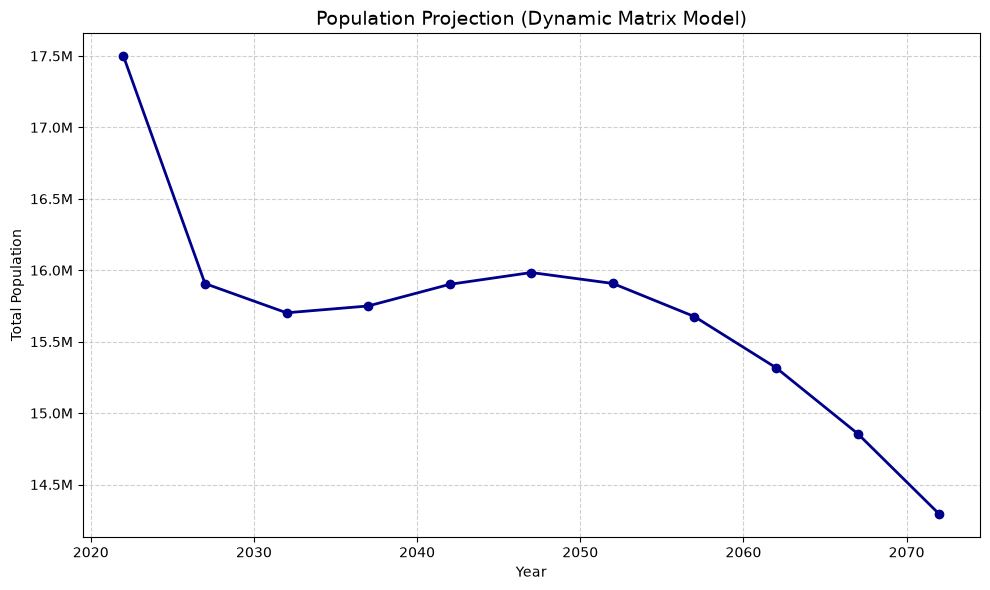


Summary:
Initial Population (2022): 17,499,623
Final Population (2072):   14,293,442
Total Change: -18.32%

---Population Chart---


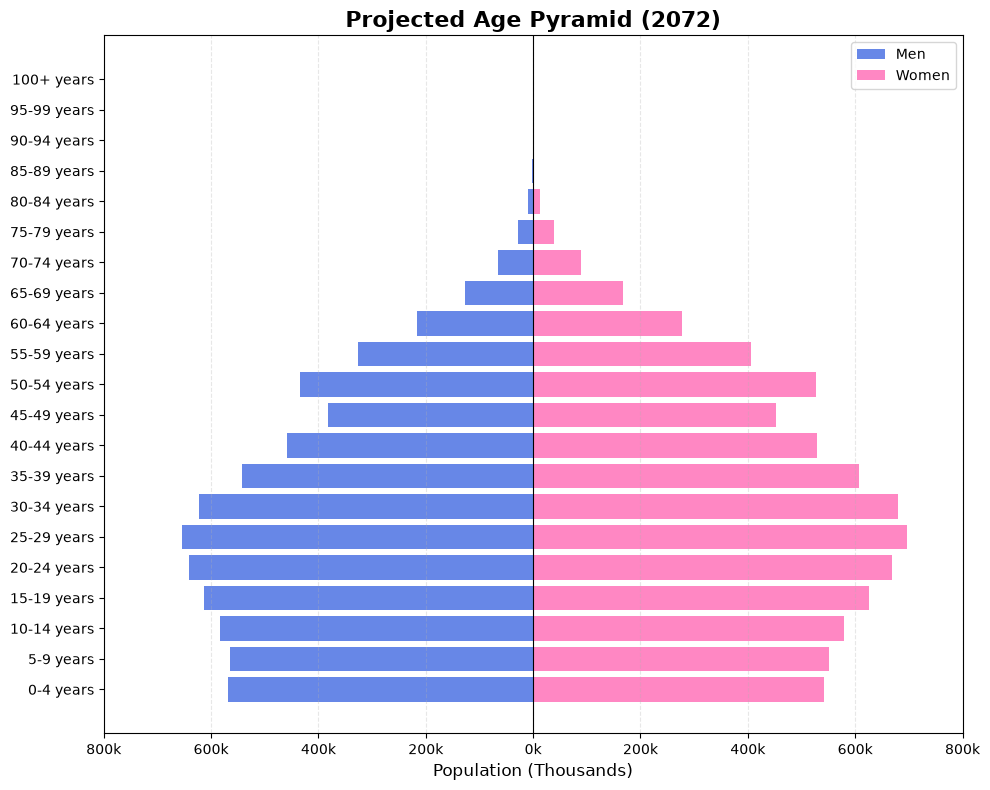

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import os

df_pop = pd.read_csv("population.csv")
df_deaths = pd.read_csv("mortality.csv")
df_fert = pd.read_csv("fertility.csv")

df_fert.set_index('Year', inplace=True)

N_STEP = 5
SEX_RATIO = 100 / 205
PCT_WOMEN = 0.515

# Initial vector
N = df_pop['2022'].values

# Process deaths (summing <1 and 1-4)
raw_deaths = df_deaths['Deaths'].values
deaths_0_4 = raw_deaths[0] + raw_deaths[1]
D = np.concatenate(([deaths_0_4], raw_deaths[2:]))

# Survival (constant)
m_rates = np.divide(D, N, out=np.zeros_like(D, dtype=float), where=N!=0)
factor = 0.5 * N_STEP
S = (1 - factor * m_rates) / (1 + factor * m_rates)
S = np.clip(S, 0, 1)

simulation_years = np.arange(2022, 2075, N_STEP)
total_history = []

print("\n--- Start of the Dynamic Simulation ---")
print(f"{'YEAR':<6} | {'TOTAL POPULATION':<18} | {'FERTILITY RATES (MEAN BY AGE GROUP)'}")
print("-" * 85)

N_2072 = None

for year in simulation_years:
    current_pop = np.sum(N)
    total_history.append(current_pop)


    if year == 2072:
        N_2072 = N.copy()

    # 2. Build the Leslie matrix (L) for this year
    k = len(N)
    L = np.zeros((k, k))

    # A. Find and print the current year's rates
    if year in df_fert.index:
        year_rates = df_fert.loc[year]
    else:
        # Fall back to the nearest available year
        available_years = df_fert.index.values
        reference_year = available_years[available_years <= year].max()
        year_rates = df_fert.loc[reference_year]

    # Show the rates used in this iteration to demonstrate that they change
    # Format for readable output
    rates_text = "  ".join([f"{v:.4f}" for v in year_rates.values])
    print(f"{year:<6} | {current_pop:,.0f}".ljust(27) + f" | [{rates_text}]")
    # ---------------------------

    groups = df_pop['Age_Group'].values
    for i, age_group in enumerate(groups):
        if age_group in year_rates.index:
            # Fill the first row of the matrix
            L[0, i] = year_rates[age_group] * N_STEP * PCT_WOMEN

    # B. Fill in survival
    for i in range(k - 1):
        L[i+1, i] = S[i]
    L[-1, -1] = S[-1]

    # 3. Project
    N = np.dot(L, N)

plt.figure(figsize=(10, 6))
plt.plot(simulation_years, total_history, marker='o', color='darkblue', linewidth=2)
plt.title("Population Projection (Dynamic Matrix Model)", fontsize=14)
plt.xlabel("Year")
plt.ylabel("Total Population")
plt.grid(True, linestyle='--', alpha=0.6)
plt.gca().yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, p: f'{x/1e6:.1f}M'))
plt.tight_layout()
plt.show()

# Final result
growth = ((total_history[-1] - total_history[0]) / total_history[0]) * 100
print(f"\nSummary:")
print(f"Initial Population (2022): {total_history[0]:,.0f}")
print(f"Final Population ({simulation_years[-1]}):   {total_history[-1]:,.0f}")
print(f"Total Change: {growth:.2f}%")

if N_2072 is not None:
    n_groups = len(N_2072)
    # Estimated future sex ratio (1.05 at birth -> 0.6 in old age)
    sex_ratio = np.linspace(1.05, 0.6, n_groups)

    pop_women = (N_2072 / (1 + sex_ratio)).astype(int)
    pop_men = N_2072 - pop_women

    fig, ax = plt.subplots(figsize=(10, 8))

    ax.barh(groups, -pop_men, color='royalblue', label='Men', alpha=0.8)
    ax.barh(groups, pop_women, color='hotpink', label='Women', alpha=0.8)

    ax.set_title('Projected Age Pyramid (2072)', fontsize=16, weight='bold')
    ax.set_xlabel('Population (Thousands)', fontsize=12)
    ax.axvline(0, color='black', linewidth=0.8)
    ax.grid(axis='x', linestyle='--', alpha=0.3)

    # Format the x-axis as positive values in thousands
    ticks = ax.get_xticks()
    ax.set_xticks(ticks)
    ax.set_xticklabels([f'{int(abs(t)/1000)}k' for t in ticks])
    print(f'\n---Population Chart---')
    ax.legend()
    plt.tight_layout()
    plt.show()

### Discussion of Results

1.  **Limitations of linearity:**
    The model incorporates time-varying rates, which is a significant advance over the previous models. However, the simulation adopted a linear reduction in fertility rates as a simplification. In real demography, the fertility transition is rarely linear, and it can show plateaus, accelerations, or fluctuations influenced by non-deterministic socioeconomic factors.

2.  **Advantage of age structure:**
    The age pyramids show the main advantage of matrix modeling over aggregate models (logistic and exponential). It breaks down population growth, revealing not only how many people there will be but who they will be, which is vital for planning public policies focused on children, the workforce, or older adults, as discussed in the introduction.

3.  **Possible improvements:**
    Beyond the question of linearity, a fully complete model like the one used by IBGE would need to treat mortality and the share of women as variables as well. In reality, they are not expected to be linear, and a detailed study would be needed to find plausible values for these rates over time.

[IBGE conceptual basis](https://biblioteca.ibge.gov.br/visualizacao/livros/liv101597.pdf) (in Portuguese)

# Model Comparison

With the theoretical basis and the individual applications in place, we create a chart showing the evolution of the 3 models through the year 2200. The period was extended to make the limitations of each approach more evident.

/tmp/ipykernel_45205/3932589400.py:11: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_fert.set_index('Year', inplace=True)


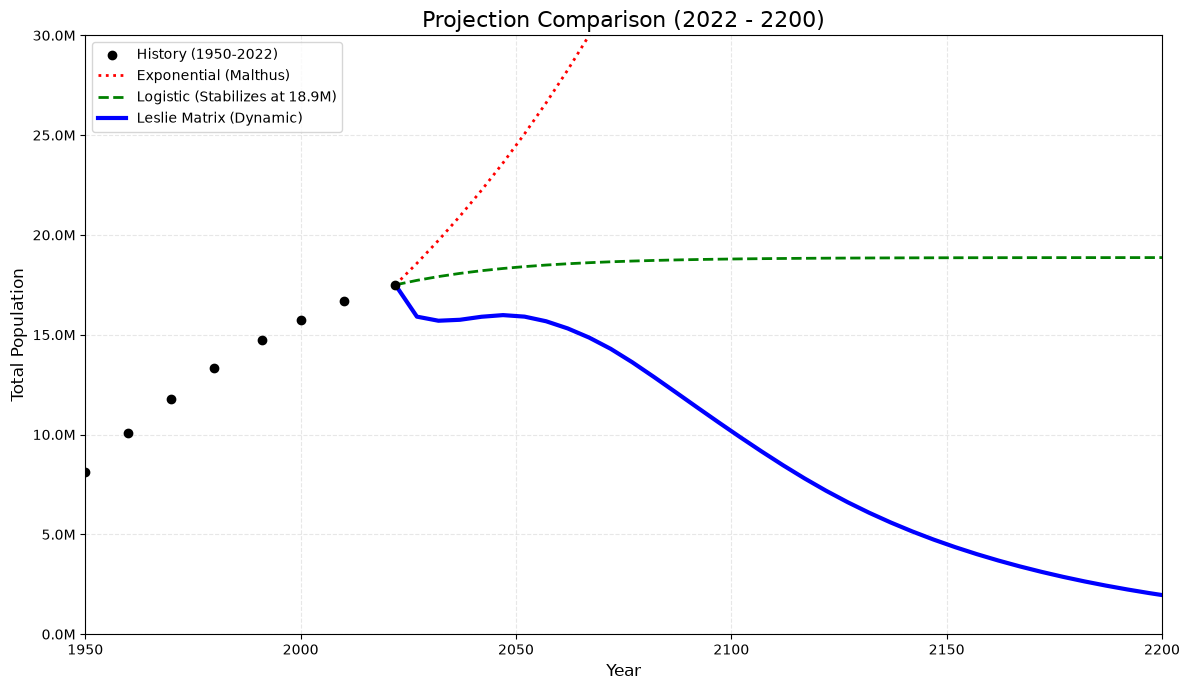

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy.optimize import curve_fit

try:
    df_pop = pd.read_csv("population.csv")
    df_deaths = pd.read_csv("mortality.csv")
    df_fert = pd.read_csv("fertility.csv")
    df_fert.set_index('Year', inplace=True)
except FileNotFoundError:
    print("Error: Files not found.")

N_STEP = 5
PCT_WOMEN = 0.515
N = df_pop['2022'].values
INITIAL_POP_2022 = np.sum(N) # Starting point

# Mortality
raw_deaths = df_deaths['Deaths'].values
if len(raw_deaths) == len(N) + 1:
    deaths_0_4 = raw_deaths[0] + raw_deaths[1]
    D = np.concatenate(([deaths_0_4], raw_deaths[2:]))
else:
    D = raw_deaths

# Survival
with np.errstate(divide='ignore', invalid='ignore'):
    m_rates = np.divide(D, N, out=np.zeros_like(D, dtype=float), where=N!=0)
factor = 0.5 * N_STEP
S = np.clip((1 - factor * m_rates) / (1 + factor * m_rates), 0, 1)

sim_years = np.arange(2022, 2205, N_STEP)
res_leslie = []

current_N = np.copy(N)

for year in sim_years:
    res_leslie.append(np.sum(current_N))

    k = len(current_N)
    L = np.zeros((k, k))

    # Rates for the year
    if year in df_fert.index:
        rates = df_fert.loc[year]
    else:
        rates = df_fert.iloc[-1] # Keep the last value if the rates run out

    for i, fx in enumerate(df_pop['Age_Group']):
        if fx in rates.index:
            L[0, i] = rates[fx] * N_STEP * PCT_WOMEN

    for i in range(k-1): L[i+1, i] = S[i]
    L[-1, -1] = S[-1]

    current_N = np.dot(L, current_N)

# History
cols_hist = [str(y) for y in [1950, 1960, 1970, 1980, 1991, 2000, 2010, 2022]]
hist_years = np.array([int(y) for y in cols_hist])
hist_pop = df_pop[cols_hist].sum().values

# Mathematical functions
def exponential(t, r, P0): return P0 * np.exp(r * t)
def logistic(t, K, r, P0): return K / (1 + ((K - P0) / P0) * np.exp(-r * t))

# Fit past data to find the trend's r and K
t_fit = hist_years - 1950

popt_log, _ = curve_fit(lambda t,K,r: logistic(t,K,r,hist_pop[0]), t_fit, hist_pop, p0=[20e6, 0.03])
K_fit, r_fit = popt_log

popt_exp, _ = curve_fit(lambda t,r: exponential(t,r,hist_pop[0]), t_fit, hist_pop, p0=[0.03])
r_exp = popt_exp[0]

t_proj = sim_years - 2022

y_exp = exponential(t_proj, r_exp, INITIAL_POP_2022)
y_log = logistic(t_proj, K_fit, r_fit, INITIAL_POP_2022)

# Plot
plt.figure(figsize=(12, 7))

plt.scatter(hist_years, hist_pop, color='black', label='History (1950-2022)', zorder=10)

# Projections (starting in 2022)
plt.plot(sim_years, y_exp, 'r:', linewidth=2, label='Exponential (Malthus)')
plt.plot(sim_years, y_log, 'g--', linewidth=2, label=f'Logistic (Stabilizes at {K_fit/1e6:.1f}M)')
plt.plot(sim_years, res_leslie, 'b-', linewidth=3, label='Leslie Matrix (Dynamic)')

plt.title('Projection Comparison (2022 - 2200)', fontsize=16)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Total Population', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.3)
plt.gca().yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, p: f'{x/1e6:.1f}M'))

# Fix the scale to focus on the logistic vs. Leslie difference
# Cut off the exponential when it explodes
plt.ylim(0, 30000000)
plt.xlim(1950, 2200)

plt.legend(loc='upper left')
plt.tight_layout()
plt.savefig('final_model_comparison.png')
plt.show()

### Conclusion and Model Limitations

The comparative analysis showed the increasing complexity needed to represent demographic reality. The **exponential model** proved inadequate for the long term because of its premise of infinite resources, resulting in explosive, unrealistic growth. The **logistic model** corrected this flaw by introducing the carrying capacity ($K$), but it proved static: on reaching the limit, the population stagnates, failing to predict the natural population decline observed in developed nations. The **matrix model (Leslie)** proved superior by incorporating age structure and demographic inertia, correctly capturing the population peak. However, the current implementation, based on a **linear** reduction in fertility rates, tends to lead the population to continuous decline in the very long term. For a more definitive model, the linear rate projection would need to be replaced by a detailed study of socioeconomic behavior, modeling how fertility tends to stabilize (rather than fall indefinitely), which would make it possible to predict not only the decline but also the new equilibrium point of future society.